In [43]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [44]:
def haar_1d(row):
  n = len(row)
  approx = (row[0::2] + row[1::2]) / 2.0
  detail = (row[0::2] - row[1::2]) / 2.0
  return np.concatenate([approx, detail])

In [45]:
def haar_2d_level(image_block):
  h, w = image_block.shape
  row_transformed = np.zeros_like(image_block, dtype=np.float32)

  for i in range(h):
    row_transformed[i, :] = haar_1d(image_block[i, :])

  col_transformed = np.zeros_like(image_block, dtype=np.float32)
  for j in range(w):
    col_transformed[:, j] = haar_1d(row_transformed[:, j])

  return col_transformed

In [46]:
image_path = 'image512.jpg'
image = cv2.imread(image_path)
img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32)

In [47]:
h, w = img_gray.shape

In [48]:
res_step1 = img_gray.copy()
res_step2 = img_gray.copy()
res_step3 = img_gray.copy()

In [49]:
res_step1 = haar_2d_level(res_step1)

curr_h1, curr_w1 = h // 2, w // 2
res_step2[:h, :w] = res_step1  
res_step2[:curr_h1, :curr_w1] = haar_2d_level(res_step2[:curr_h1, :curr_w1])

curr_h2, curr_w2 = h // 4, w // 4
res_step3[:h, :w] = res_step2 
res_step3[:curr_h2, :curr_w2] = haar_2d_level(res_step3[:curr_h2, :curr_w2])

In [50]:
def normalize_img(img):
    norm = cv2.normalize(
        img, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX
    )
    return np.uint8(norm)

In [51]:
vis_1 = normalize_img(res_step1)
vis_2 = normalize_img(res_step2)
vis_3 = normalize_img(res_step3)

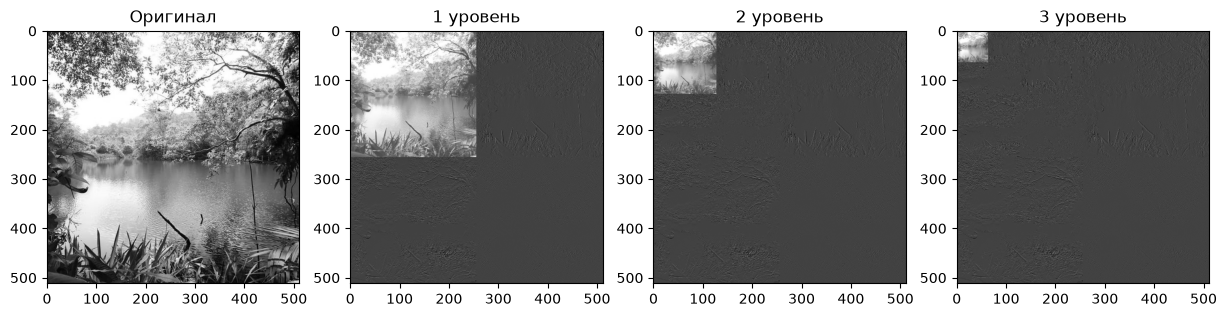

In [52]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 4, 2)
plt.imshow(vis_1, cmap='gray')
plt.title('1 уровень')

plt.subplot(1, 4, 3)
plt.imshow(vis_2, cmap='gray')
plt.title('2 уровень')

plt.subplot(1, 4, 4)
plt.imshow(vis_3, cmap='gray')
plt.title('3 уровень')

plt.show()

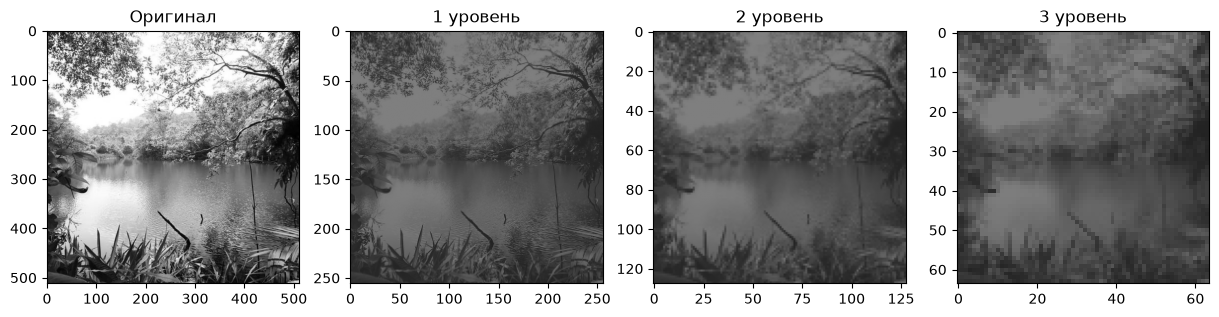

In [53]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 4, 2)
plt.imshow(vis_1[:256, :256], cmap='gray', vmin=0, vmax=512)
plt.title('1 уровень')

plt.subplot(1, 4, 3)
plt.imshow(vis_2[:128, :128], cmap='gray', vmin=0, vmax=512)
plt.title('2 уровень')

plt.subplot(1, 4, 4)
plt.imshow(vis_3[:64, :64], cmap='gray', vmin=0, vmax=512)
plt.title('3 уровень')

plt.show()